Car Price Prediction

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
columns = [
    'symboling',
    'normalized-losses',
    'make',
    'fuel-type',
    'aspiration',
    'num-of-doors',
    'body-style',
    'drive-wheels',
    'engine-location',
    'wheel-base',
    'length',
    'width',
    'height',
    'curb-weight',
    'engine-type',
    'num-of-cylinders',
    'engine-size',
    'fuel-system',
    'bore',
    'stroke',
    'compression-ratio',
    'horsepower',
    'peak-rpm',
    'city-mpg',
    'highway-mpg',
    'price'
]

In [3]:
df = pd.read_csv(
    "auto_imports.csv",
    names=columns
)

In [4]:
df.shape

(201, 26)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    object 
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       201 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

In [6]:
df.describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,compression-ratio,city-mpg,highway-mpg,price
count,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,98.797015,174.200995,65.889055,53.766667,2555.666667,126.875622,10.164279,25.179104,30.686567,13207.129353
std,1.254802,6.066366,12.322175,2.101471,2.447822,517.296727,41.546834,4.004965,6.423220,6.815150,7947.066342
min,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.500000,166.800000,64.100000,52.000000,2169.000000,98.000000,8.600000,19.000000,25.000000,7775.000000
50%,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,9.000000,24.000000,30.000000,10295.000000
75%,2.000000,102.400000,183.500000,66.600000,55.500000,2926.000000,141.000000,9.400000,30.000000,34.000000,16500.000000
max,3.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000,45400.000000


In [7]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [8]:
# Handling missing values
df['normalized-losses'] = df['normalized-losses'].replace(['?', '0'], np.nan)
df['normalized-losses'] = pd.to_numeric(df['normalized-losses'])
df['normalized-losses'].isnull().sum()

np.int64(37)

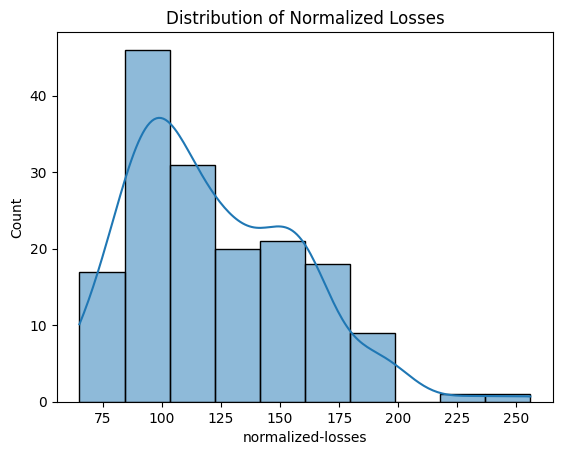

In [9]:
sns.histplot(df['normalized-losses'], kde=True)

plt.title("Distribution of Normalized Losses")

plt.show()

In [10]:
df['normalized-losses'].median()

np.float64(115.0)

In [11]:
df['normalized-losses'].fillna(
    df['normalized-losses'].median(),
    inplace=True
)

/var/folders/yd/zq8l66dn32l1j2rdhnbd61_m0000gn/T/ipykernel_1576/390440073.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['normalized-losses'].fillna(


In [12]:
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['num-of-doors'].value_counts()

num-of-doors
four    113
two      86
?         2
Name: count, dtype: int64

In [15]:
df['num-of-doors'] = df['num-of-doors'].replace('?', '4')
df['num-of-doors'] = df['num-of-doors'].replace('four','4')
df['num-of-doors'] = df['num-of-doors'].replace('two','2')
df['num-of-doors'] = pd.to_numeric(df['num-of-doors'])
df['num-of-doors'].value_counts()

num-of-doors
4    115
2     86
Name: count, dtype: int64

In [16]:
df = df.replace('?', np.nan)
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 4
stroke               4
compression-ratio    0
horsepower           2
peak-rpm             2
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [17]:
num_cols = ['bore', 'stroke',
            'horsepower', 'peak-rpm', 'price']

for col in num_cols:
    df[col] = pd.to_numeric(df[col])

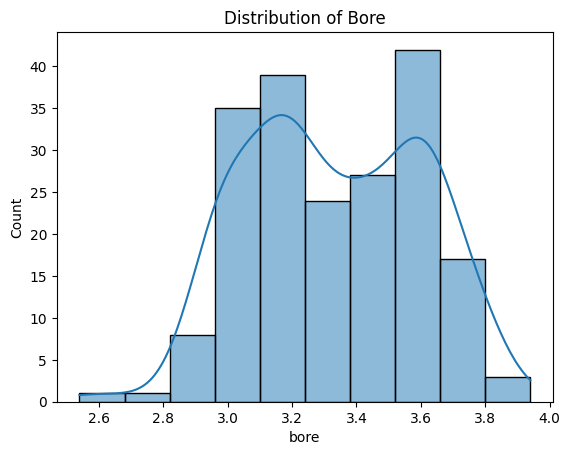

In [18]:
sns.histplot(df['bore'], kde=True)

plt.title("Distribution of Bore")

plt.show()

In [19]:
df['bore'] = df['bore'].fillna(
    df['bore'].median()
)

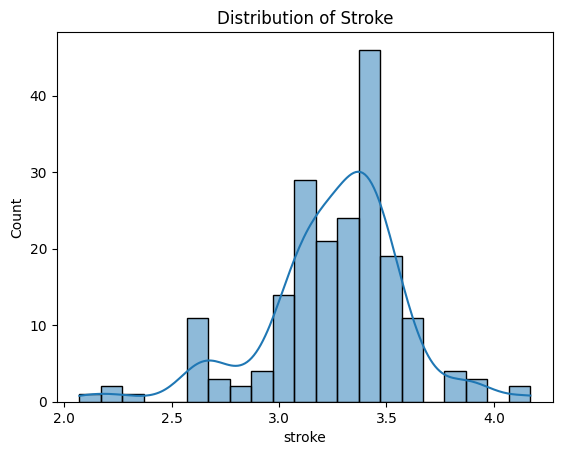

In [20]:
sns.histplot(df['stroke'], kde=True)

plt.title("Distribution of Stroke")

plt.show()

In [21]:
df['stroke'] = df['stroke'].fillna(
    df['stroke'].median()
)

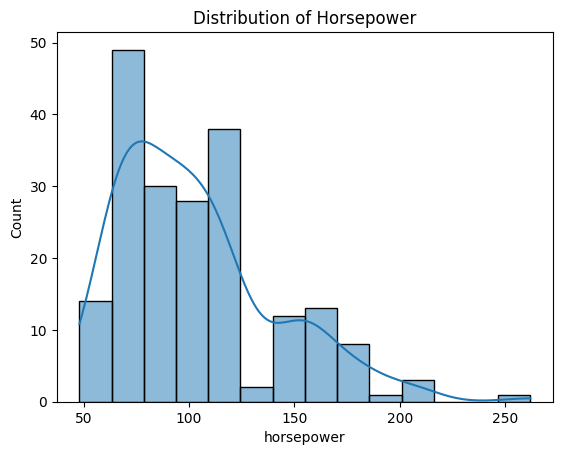

In [22]:
sns.histplot(df['horsepower'], kde=True)

plt.title("Distribution of Horsepower")

plt.show()

In [23]:
df['horsepower'] = df['horsepower'].fillna(
    df['horsepower'].median()
)

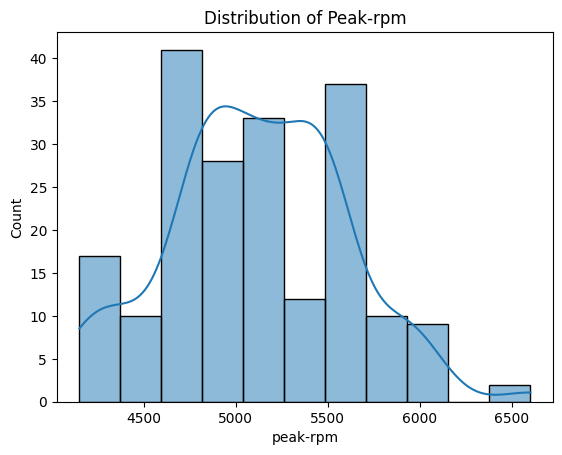

In [24]:
sns.histplot(df['peak-rpm'], kde=True)

plt.title("Distribution of Peak-rpm")

plt.show()

In [25]:
df['peak-rpm'] = df['peak-rpm'].fillna(
    df['peak-rpm'].median()
)

In [26]:
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [27]:
df['make'].value_counts()

make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
chevrolet         3
alfa-romero       3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

In [28]:
df['fuel-type'].value_counts()

fuel-type
gas       181
diesel     20
Name: count, dtype: int64

In [29]:
df['aspiration'].value_counts()

aspiration
std      165
turbo     36
Name: count, dtype: int64

In [30]:
df['body-style'].value_counts()

body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

In [31]:
df['drive-wheels'].value_counts()

drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

In [32]:
df['engine-location'].value_counts()

engine-location
front    198
rear       3
Name: count, dtype: int64

In [33]:
df['engine-type'].value_counts()

engine-type
ohc      145
ohcf      15
ohcv      13
dohc      12
l         12
rotor      4
Name: count, dtype: int64

In [34]:
df['num-of-cylinders'].value_counts()

num-of-cylinders
four      157
six        24
five       10
eight       4
two         4
twelve      1
three       1
Name: count, dtype: int64

In [35]:
df['num-of-cylinders'] = df['num-of-cylinders'].replace('four', '4')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('six','6')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('five','5')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('eight', '8')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('two','2')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('twelve','12')
df['num-of-cylinders'] = df['num-of-cylinders'].replace('three','3')
df['num-of-cylinders'] = pd.to_numeric(df['num-of-cylinders'])
df['num-of-cylinders'].value_counts()

num-of-cylinders
4     157
6      24
5      10
8       4
2       4
12      1
3       1
Name: count, dtype: int64

In [36]:
df['fuel-system'].value_counts()

fuel-system
mpfi    92
2bbl    64
idi     20
1bbl    11
spdi     9
4bbl     3
mfi      1
spfi     1
Name: count, dtype: int64

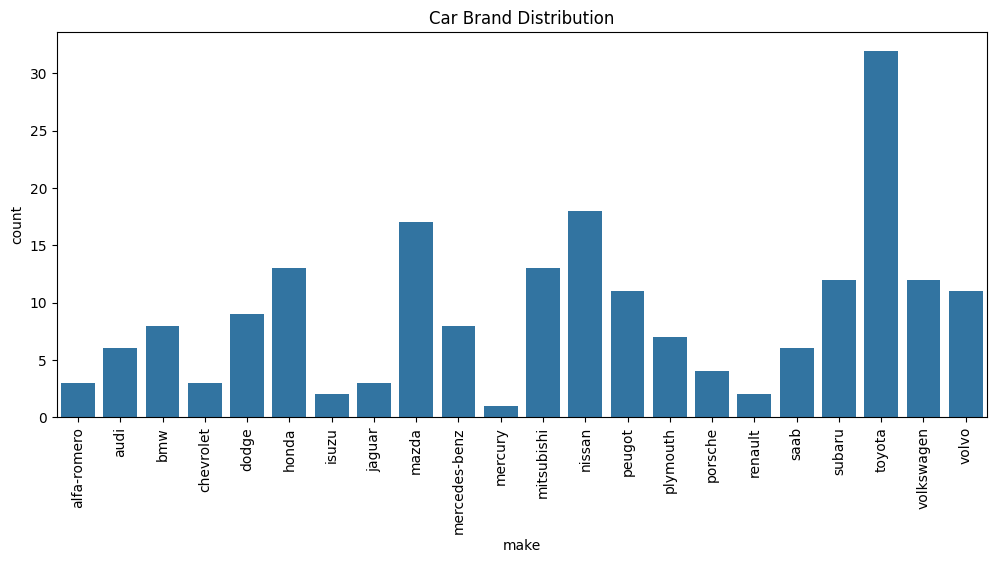

In [37]:
plt.figure(figsize=(12,5))
sns.countplot(x='make', data=df)
plt.xticks(rotation=90)
plt.title("Car Brand Distribution")
plt.show()

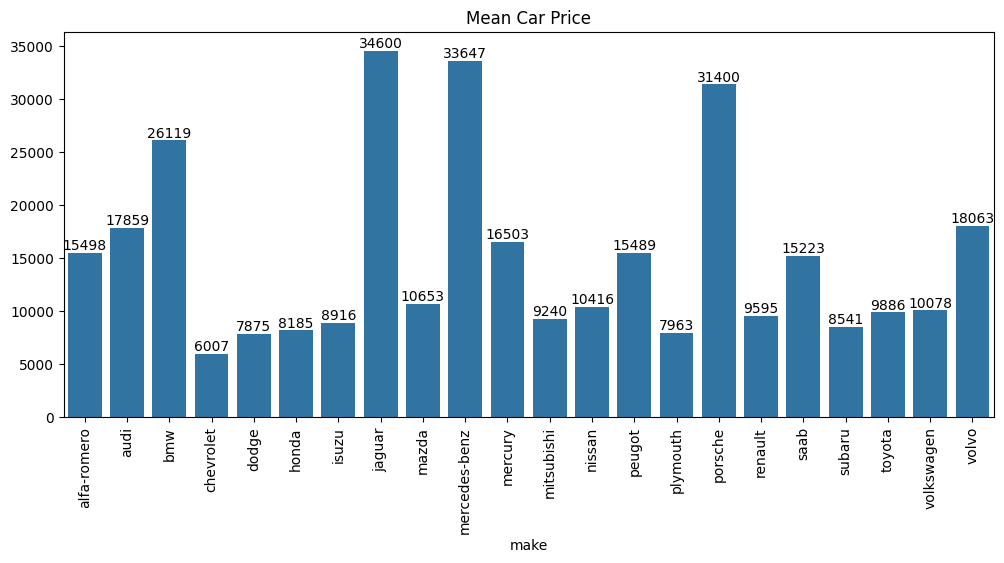

In [54]:
mean_price_make = df.groupby('make')['price'].mean()

plt.figure(figsize=(12,5))

ax = sns.barplot(
    x=mean_price_make.index,
    y=mean_price_make.values
)

# Add values on bars
for i in ax.containers:
    ax.bar_label(i, fmt='%.0f')

plt.xticks(rotation=90)

plt.title("Mean Car Price")

plt.show()

In [55]:
mean_price_make = mean_price_make.sort_values()
print(
    f"The car with the maximum average value is "
    f"{mean_price_make.idxmax()} "
    f"with the average price of "
    f"{mean_price_make.max()}"
)
print(
    f"The car with the minimum average value is "
    f"{mean_price_make.idxmin()} "
    f"with the average price of "
    f"{mean_price_make.min()}"
)
print("Average Car Price of all cars is", df['price'].mean())

The car with the maximum average value is jaguar with the average price of 34600.0
The car with the minimum average value is chevrolet with the average price of 6007.0
Average Car Price of all cars is 13207.129353233831


In [56]:
cat_cols = df.select_dtypes(include='object').columns
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [57]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,115.0,0,1,0,2,0,2,0,88.6,...,130,5,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,115.0,0,1,0,2,0,2,0,88.6,...,130,5,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,115.0,0,1,0,2,2,2,0,94.5,...,152,5,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,1,1,0,4,3,1,0,99.8,...,109,5,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,1,1,0,4,3,0,0,99.4,...,136,5,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [58]:
X = df.drop('price', axis=1)

y = df['price']

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [60]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [61]:
lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

In [62]:
print("Linear Regression")

print("MAE:",
      mean_absolute_error(y_test, y_pred_lr))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_lr)))

print("R2 Score:",
      r2_score(y_test, y_pred_lr))

Linear Regression
MAE: 2793.5835858866394
RMSE: 4215.06484544367
R2 Score: 0.8547834879201327


In [63]:
svr = SVR(
    kernel='rbf',
    C=100,
    gamma=0.01,
    epsilon=0.1
)

svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

In [64]:
print("SVR")

print("MAE:",
      mean_absolute_error(y_test, y_pred_svr))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_svr)))

print("R2 Score:",
      r2_score(y_test, y_pred_svr))

SVR
MAE: 7005.062446170376
RMSE: 11174.518523005427
R2 Score: -0.0206224575829006


In [65]:
dt = DecisionTreeRegressor(
    random_state=42,
    max_depth=5
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

In [66]:
print("Decision Tree Regressor")

print("MAE:",
      mean_absolute_error(y_test, y_pred_dt))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_dt)))

print("R2 Score:",
      r2_score(y_test, y_pred_dt))

Decision Tree Regressor
MAE: 2021.3118040852316
RMSE: 3145.079156998239
R2 Score: 0.919151746674189


In [67]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [68]:
print("Random Forest Regressor")

print("MAE:",
      mean_absolute_error(y_test, y_pred_rf))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_rf)))

print("R2 Score:",
      r2_score(y_test, y_pred_rf))

Random Forest Regressor
MAE: 1810.1445022148614
RMSE: 2931.755627849676
R2 Score: 0.9297473006859026


Data Analysis Report 
1. The data had some missing values which had to be handled.
2. Few columns which were numerical data were object type which had to be converted to numerical.
3. 2 columns had discrete numerical values which were written in categorical format which had to be changed.
4. Categorical columns had to be Label Encoded.
5. From the data we find that the highest selling car is Toyota and least is Mercury.
6. The mean prices of all car brands were compared and plotted on a chart from which we can see that the Jaguar has the highest average value whereas Chevrolet has the least.
7. Finally we split the data into train test and scaled the data using Standard Scaler. 

Model Evaluation Report 
We used 4 models to predict the price. 
1. Linear Regression: This model gave an R2 score of 0.85.
2. SVR: This model did not work well with this model maybe because of the data complexity or it needs more tuning. The R2 score here was -0.02 so this model failed.
3. Decision Tree Regressor: This model gave an R2 score of 0.91.
4. Random Forest Regressor: Finally this model gave a slightly better R2 score of 0.92.

   So we decided to finalize on Random Forest Classifier. 


Challenges Faced 
1. The dataset had many columns which had missing values which were difficult to spot. We applied data science techniques and handled them.
2. The columns did not have headers so we had to add headers. We also had to change the datatype of many columns for a better training data.
3. Overall we faced difficulty in buildng the models as the first 2 models were not giving the desired results. But finally we arrived at the model which gave us the best acuracy. 